# IST_robot：10–15 Hz 平均升力扫描

每隔 1 Hz 取点，固定基座、被动羽化与气动/电机参数保持一致。
通过调节速度指令补偿负载误差，实测频率误差不超过 0.01 Hz。
每组运行 2 s，排除前 0.6 s，仅在完整曲柄周期内积分并按时间加权平均。
Fz 为左右翼合计的世界坐标气动力，正值向上。15 Hz 点复用此前同参数实验的原始记录并重新计算。
图中误差棒表示各周期平均升力的最小值和最大值，**不是置信区间或模型误差**。

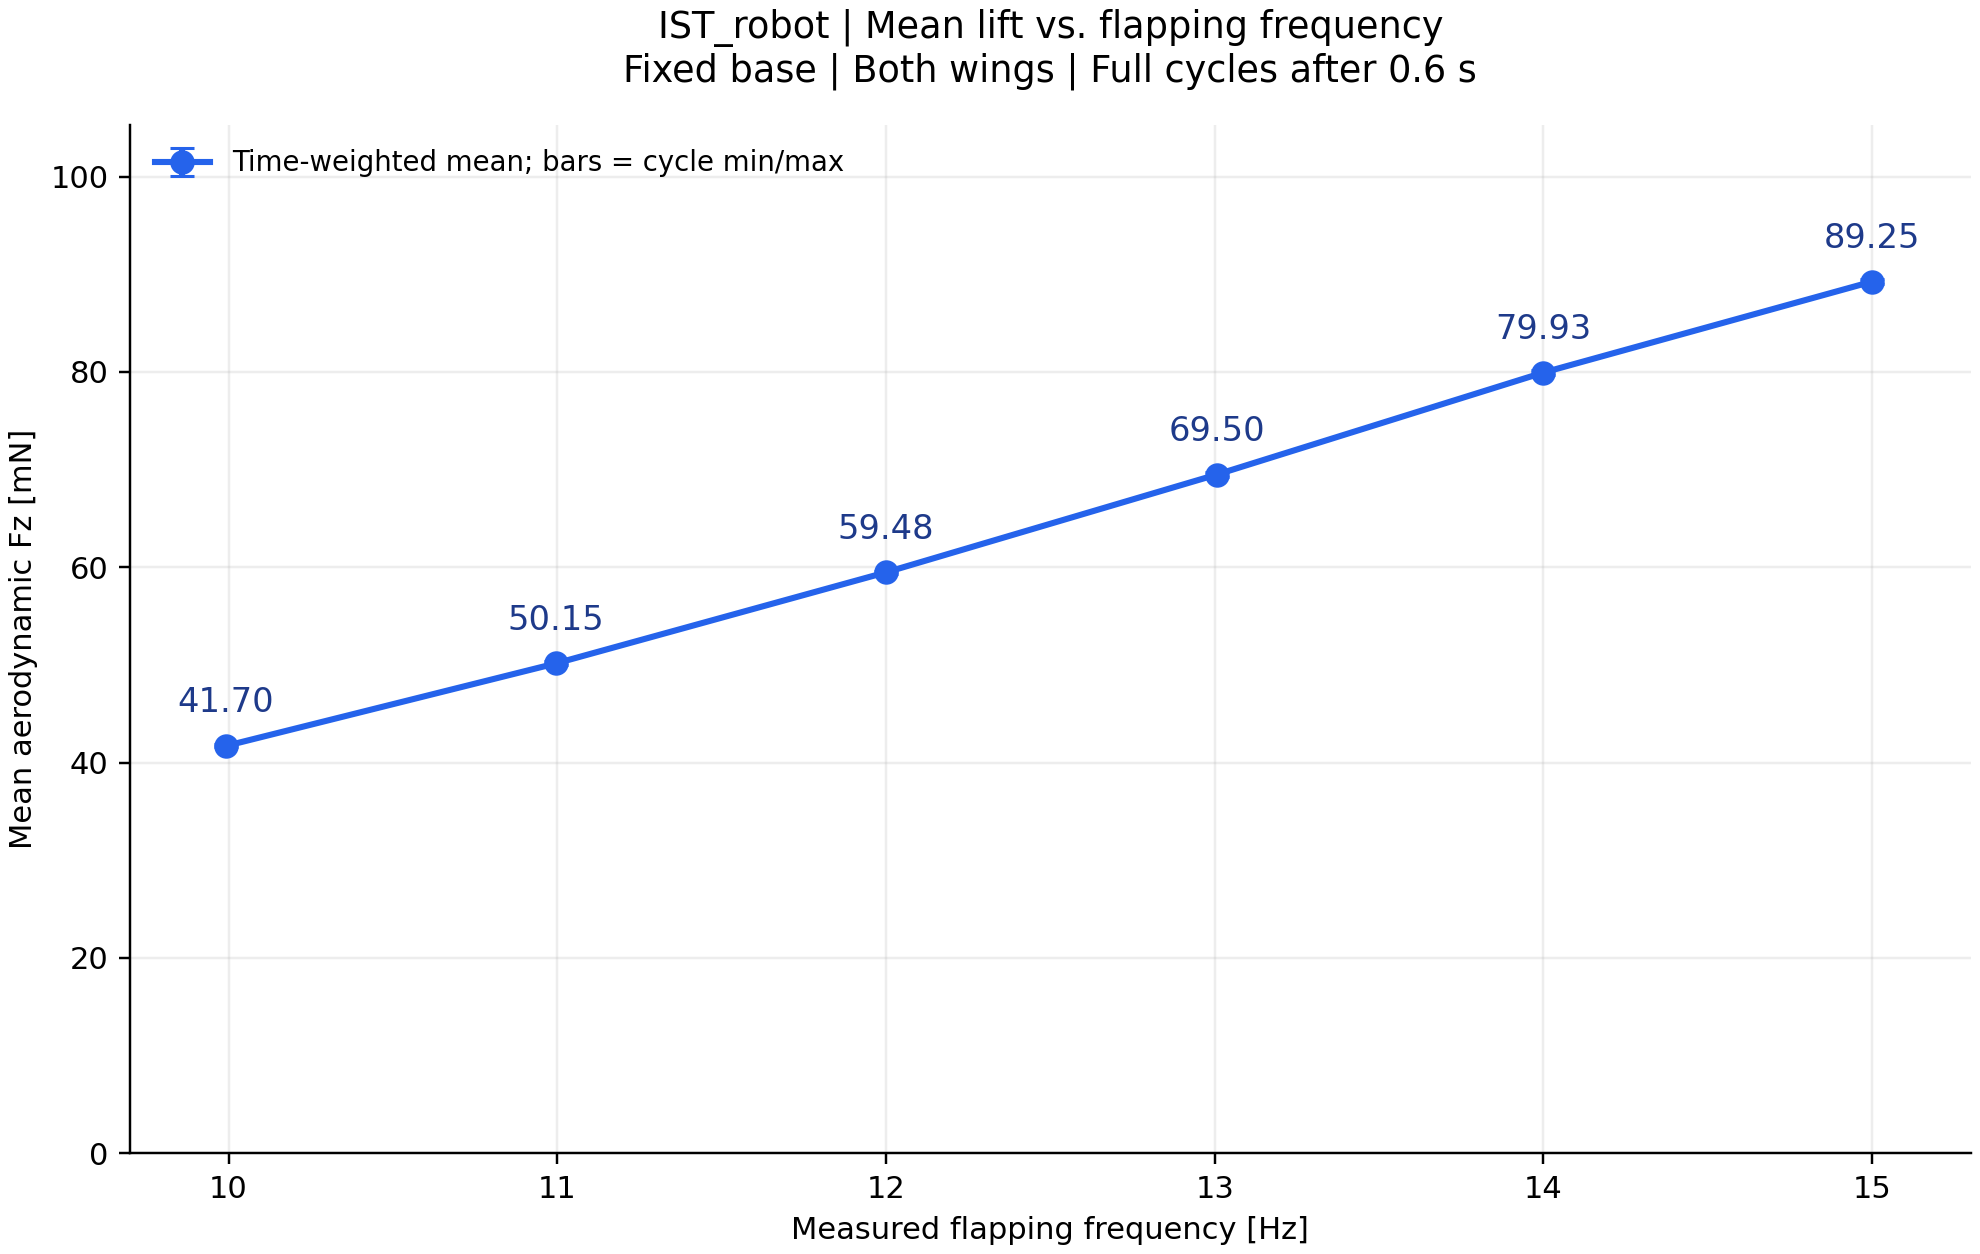

| 目标 Hz | 实测 Hz | 平均 Fz / mN | 完整周期数 |
|---:|---:|---:|---:|
| 10 | 9.9911 | 41.700 | 13 |
| 11 | 10.9950 | 50.150 | 15 |
| 12 | 12.0000 | 59.483 | 16 |
| 13 | 13.0063 | 69.497 | 18 |
| 14 | 13.9986 | 79.931 | 18 |
| 15 | 14.9992 | 89.252 | 20 |

In [1]:
from pathlib import Path
import sys, json
import numpy as np
from IPython.display import display, Image, Markdown
here = Path.cwd().resolve()
ROOT = next(p for p in (here, *here.parents) if (p / 'flapsim' / 'simulator.py').is_file())
FOLDER = ROOT / 'experiments' / 'fixbase'
sys.path.insert(0, str(FOLDER))
from sweep_frequency import saved_run, plot_sweep, TOLERANCE_HZ
from run_15hz import cycle_statistics
OUTPUT = FOLDER / 'results_10_15hz'
results = json.loads((OUTPUT / 'sweep.json').read_text())
assert len(results) == 6
for r in results:
    data, summary = saved_run(FOLDER / r['source_folder'])
    calculated = cycle_statistics(data, target_hz=r['target_wing_frequency_hz'])
    assert abs(calculated['measured_wing_frequency_hz']-r['target_wing_frequency_hz']) <= TOLERANCE_HZ
    assert np.isclose(calculated['mean_lift_N'], r['mean_lift_N'])
plot_sweep(results)
display(Image(filename=str(OUTPUT / 'mean_Fz_vs_frequency.png')))
rows = ['| 目标 Hz | 实测 Hz | 平均 Fz / mN | 完整周期数 |', '|---:|---:|---:|---:|']
rows += [f"| {r['target_wing_frequency_hz']} | {r['measured_wing_frequency_hz']:.4f} | {r['mean_lift_mN']:.3f} | {r['complete_cycles']} |" for r in results]
display(Markdown(chr(10).join(rows)))

汇总数据：`results_10_15hz/sweep.csv`、`sweep.json`。
每点 `source_folder` 指向原始 CSV/NPZ 和参数记录；各频率子目录保存调速过程。
PNG 与 SVG 图可直接导出。重新运行：`python experiments/fixbase/sweep_frequency.py`。
当前结果来自未实机标定的仿真模型。